# Macro Regime-Based Multi-Asset Allocation 

- Problème: static allocation breaks when macro conditions shift.
•	Hypothèse: asset behavior is regime-dependent.
•	Méthode: build economic and policy scores, classify regimes, map regimes to assets, backtest against SPY.
•	Message honnête: this is a regime-classification prototype, not yet a production-ready strategy.

## Investment question

Investment question 
Contenu:
•	Question testable: can a simple macro regime engine improve drawdown-adjusted allocation relative to buy-and-hold SPY?
•	Universe: SPY, TLT, GLD, DBC.
•	Benchmark: SPY.
•	Constraints: long-only, fully invested, daily close prices, next-period implementation.

## Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import plotly.graph_objects as go

import seaborn as sns

import yfinance as yf
from fredapi import Fred

import scipy.stats as stats
from scipy.stats import norm, probplot
from scipy import stats
from numpy.polynomial import polynomial as P

from statsmodels.tsa.stattools import adfuller, kpss

## Helper functions

### Economic and policy scores

#### Z-score

In [3]:
def zscore_fix(series, ref_start='1985-01-01', clip_val=2.5):
    ref = series.loc[ref_start:].dropna()
    mu    = ref.mean()
    sigma = ref.std(ddof=0)
    z = (series - mu) / sigma
    return z.clip(-clip_val, clip_val)

#### Momentum Score

In [4]:
def momentum_level(series, freq='monthly', lag=6, clip=2.5, ref_start='1985-01-01'):
    freq_map = {'daily': 21, 'monthly': 1, 'quarterly': 3}
    step = freq_map[freq]
    lag_n = lag * step

    delta = series - series.shift(lag_n) 
    ref = delta.loc[ref_start:].dropna()
    mu, sigma = ref.mean(), ref.std(ddof=0)

    z = (delta - mu) / sigma
    return z.clip(-clip, clip)

#### Visualize Regime evolution

In [5]:
def plot_regime_evolution(scores_df, end_date, window, econ_col="Econ_score", policy_col="Policy_score"):
    scores_df = scores_df.copy()
    scores_df.index = pd.to_datetime(scores_df.index)
    end_date = pd.to_datetime(end_date)

    sub = scores_df.loc[:end_date].tail(window)
    sub = sub.dropna(subset=[econ_col, policy_col])

    #if sub.empty:
    #    print("No available data on this window")
    #    return

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # --- Matrix ---
    ax = axes[0]
    n = len(sub)
    colors = plt.cm.viridis(np.linspace(0, 1, n))

    ax.scatter(sub[econ_col], sub[policy_col], c=colors, s=40, zorder=2)
    ax.plot(sub[econ_col], sub[policy_col], color="gray", alpha=0.4, linewidth=1, zorder=1)

    # Last point highlighted
    ax.scatter(sub[econ_col].iloc[-1], sub[policy_col].iloc[-1],
               color="red", s=120, marker="*", zorder=3, label="Last observation")

    ax.axvline(x=0, color="black", linewidth=1)
    ax.axhline(y=0, color="black", linewidth=1)

    lim = max(3, np.abs(sub[[econ_col, policy_col]].values).max() * 1.1)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)

    ax.set_xlabel("Econ score")
    ax.set_ylabel("Policy score")
    ax.set_title(f"Regime trajectory\n{sub.index[0].date()} → {sub.index[-1].date()} ({n} obs)")
    ax.grid(True)
    ax.legend()

    # --- Evolution on the window ---
    ax2 = axes[1]
    ax2.plot(sub.index, sub[econ_col], label="Econ score", color="tab:blue")
    ax2.plot(sub.index, sub[policy_col], label="Policy score", color="tab:orange")
    ax2.axhline(y=0, color="black", linewidth=1)
    ax2.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    fig.autofmt_xdate()

    ax2.set_title("Evolution of scores over time")
    ax2.set_ylabel("Score")
    ax2.legend()
    ax2.grid(True)

    plt.tight_layout()
    plt.show()




### Assets metrics

#### Import prices and compute returns / log return

In [6]:
def asset_data(ticker, start_date='1960-01-01'):
    data = yf.download(ticker, start=start_date, interval='1d')
    prices = data['Close']

    # In case of multi-index
    if hasattr(prices, 'columns'):
        prices = prices[ticker]

    returns = prices.pct_change().dropna()
    log_returns = np.log(prices / prices.shift(1)).dropna()

    return prices, returns, log_returns

#### Individual Performance

In [7]:
def performance(simple_returns, rf, mar = None):
    W = (1 + simple_returns).cumprod()
    n_years = (W.index[-1] - W.index[0]).days / 365.25

    #CAGR
    cagr = W.iloc[-1]**(1/n_years) - 1
    cagr = cagr.round(4)

    #Annualized Vol
    vol = simple_returns.std() * np.sqrt(252)
    vol = vol.round(4)

    #Sharpe ratio
    sharpe_d = (simple_returns.mean() - rf) / (simple_returns.std())
    sharpe = sharpe_d*np.sqrt(252)

    #Sortino ratio
    if mar is None:
        mar = rf
    downside = np.minimum(simple_returns - mar, 0.0)
    dd_daily = np.sqrt(np.mean(downside**2))          # downside deviation (daily)
    sortino = np.sqrt(252) * (simple_returns.mean() - mar) / dd_daily

    print('Parametric analysis of', simple_returns.name, ':\n',
          'CAGR:            ', round(cagr, 4), '%',
          '\n', 'Annualized Vol:  ', round(vol, 4), '%',
          '\n', 'Sharpe ratio:    ', round(sharpe, 4),
          '\n', "Sortino ratio:   ", round(sortino, 4), '\n')



#### Normal distirbution representation and Skew/kurtosis, QQplot, Probability distribution function

In [8]:
def distribution(simple_returns):
    #param
    mu, sigma = simple_returns.mean(), simple_returns.std()
    skew = simple_returns.skew()
    kurt = simple_returns.kurtosis()
    excess_kurt = kurt - 3

    print('Distribution parameters of', simple_returns.name, '\n',
          'Mean:            ', round(mu, 6), '\n',
          'Std:             ', round(sigma, 4), '\n',
          'Skewness:       ', round(skew, 4), '\n',
          'Kurtosis:       ', round(kurt, 4), '\n',
          'Excess Kurtosis:', round(excess_kurt, 4), '\n')



    fig, axes = plt.subplots(1, 2, figsize=(12,5))

    # Histogram + normale
    axes[0].hist(simple_returns, bins=100, density=True, alpha=0.6, label='Returns', edgecolor='black')
    x = np.linspace(simple_returns.min(), simple_returns.max(), 1000)
    axes[0].plot(x, norm.pdf(x, mu, sigma), 'r', label='Normal dist')
    axes[0].set_xlabel('Returns')
    axes[0].set_ylabel('Frequency')
    axes[0].set_title('Returns vs Normal distribution')
    axes[0].legend()

    # QQ-plot
    probplot(simple_returns, dist="norm", plot=axes[1])
    # Aesthetic
    for line in axes[1].get_lines():
        line.set_markersize(3)
        line.set_alpha(0.3)
    axes[1].set_title('QQ-plot vs Normal')
    axes[1].set_xlabel('Theoretical Quantiles')
    axes[1].set_ylabel('Ordered Values')

    plt.tight_layout()
    plt.show()

    print('\n')

#### Tail risk: VaR/CVaR

In [9]:
def tail_risks(log_returns, confidence_level = None, method: str = "historical"):  # "historical" | "parametric"
    #Worst day
    worst_day = log_returns.idxmin()
    worst_day_return = log_returns[worst_day].round(4)

    print("Worst day : ", worst_day,
          "\n returns : ", worst_day_return*100, "%")

    #VAR/CVAR
    if confidence_level is None:
        levels = [0.95, 0.975, 0.99]
    elif confidence_level is not None:
        levels = [0.95, 0.975, 0.99, confidence_level]

    results = []

    for cl in levels:
        alpha = 1 - cl  #5% worst scenarios for 95%

        if method == "historical":
            var = -np.percentile(log_returns, alpha * 100)
            tail = log_returns[log_returns <= -var]
            cvar = -tail.mean() if len(tail) > 0 else var

        elif method == "parametric":
            mu, sigma = log_returns.mean(), log_returns.std(ddof=1)
            var = -(mu + sigma * stats.norm.ppf(alpha))
            cvar = -(mu - sigma * stats.norm.pdf(stats.norm.ppf(alpha)) / alpha)

        results.append({
            "Confidence Level": f"{cl*100:.1f}%",
            "Alpha (tail)": f"{alpha*100:.1f}%",
            "VaR": f"{var*100:.3f}%",
            "CVaR / ES": f"{cvar*100:.3f}%",
         })

    return pd.DataFrame(results).set_index("Confidence Level")

#### Max drawdown, TUW

In [10]:
def drawdowns2(prices):
    prices = prices.dropna()
    running_max = prices.cummax()
    dd_series = (prices - running_max) / running_max

    # --- Identifier les épisodes ---
    is_uw = dd_series < 0
    episodes = []
    i = 0
    n = len(prices)

    while i < n:
        if is_uw.iloc[i]:
            # Début de l'épisode : le pic est le jour AVANT
            peak_pos = i - 1 if i > 0 else 0
            peak_date = prices.index[peak_pos]
            j = i
            # Avancer jusqu'à la fin de l'épisode
            while j < n and is_uw.iloc[j]:
                j += 1
            # [i, j-1] = période sous l'eau
            trough_pos  = dd_series.iloc[i:j].values.argmin() + i
            trough_date = prices.index[trough_pos]
            max_dd      = dd_series.iloc[trough_pos]

            if j < n:
                recovery_date = prices.index[j]
                tuw           = j - peak_pos          # pic → recovery
                recovery_time = j - trough_pos        # creux → recovery
            else:
                recovery_date = None
                tuw           = n - 1 - peak_pos      # ongoing
                recovery_time = None

            episodes.append({
                "Peak":            peak_date,
                "Trough":          trough_date,
                "Recovery":        recovery_date,
                "Max DD (%)":      round(max_dd * 100, 2),
                "TUW (periods)":   tuw,
                "Recovery time":   recovery_time,
            })
            i = j  # reprendre après l'épisode
        else:
            i += 1

    tuw_table = pd.DataFrame(episodes)

    # --- Épisode le plus long (TUW max) ---
    longest = tuw_table.loc[tuw_table["TUW (periods)"].replace("ongoing", pd.NA)
                              .astype(float).idxmax()]

    # --- Épisode le plus profond (Max DD min) ---
    deepest = tuw_table.loc[tuw_table["Max DD (%)"].idxmin()]

    return {
        "drawdown_series": dd_series,
        "tuw_table":       tuw_table,
        "longest_dd":      longest,
        "deepest_dd":      deepest,
    }


#### Cov/Corr Matrix

In [11]:
def cov_corr_matrix(log_returns):
  #entry must be a df

  #covariance matrix
  cov_matrix = log_returns.cov() * 252 * 100  # en unités de %²

  fig, axes = plt.subplots(1, 2, figsize=(16, 6))
  sns.heatmap(cov_matrix, annot=True, cmap='coolwarm',
            fmt='.3f', ax=axes[0])
  axes[0].set_title('Covariance Matrix (Annualized)')

  #correlation_matrix
  corr_matrix = log_returns.corr()
  sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',
            fmt='.3f', vmin=-1, vmax=1, ax=axes[1])
  axes[1].set_title('Correlation Matrix')

#### Rolling correlation, Scatter plot + regression, Rolling volatility and Summary statistics

In [12]:
def analyze_pair(log_returns, asset_a: str, asset_b: str, windows: list[int] = [126, 252]):
    a = log_returns[asset_a]
    b = log_returns[asset_b]

    # Rolling correlation
    rolling_corr_126 = a.rolling(126).corr(b)
    rolling_corr_252 = a.rolling(252).corr(b)
    mean_corr = rolling_corr_252.mean()
    std_corr  = rolling_corr_252.std()

    # Beta OLS
    mask = a.notna() & b.notna()
    beta, alpha = np.polyfit(b[mask], a[mask], 1)
    ss_res = np.sum((a[mask] - (beta * b[mask] + alpha))**2)
    ss_tot = np.sum((a[mask] - a[mask].mean())**2)
    r2 = 1 - ss_res / ss_tot

    # Rolling vol
    vol_a = a.rolling(126).std() * np.sqrt(252)
    vol_b = b.rolling(126).std() * np.sqrt(252)

    #Plot:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    fig.suptitle(f'{asset_a} vs {asset_b}', fontsize=14)

    # Plot 1 : rolling correlation
    axes[0,0].plot(rolling_corr_126, label='126d', alpha=0.8)
    axes[0,0].plot(rolling_corr_252, label='252d', linewidth=2)
    axes[0,0].axhline(0, color='black', linestyle='--', linewidth=0.8)
    axes[0,0].set_title('Rolling Correlation')
    axes[0,0].legend()

    # Plot 2 : scatter + beta
    axes[0,1].scatter(b[mask], a[mask], alpha=0.3, s=10)
    x_line = np.linspace(b[mask].min(), b[mask].max(), 100)
    axes[0,1].plot(x_line, beta * x_line + alpha, color='red')
    axes[0,1].set_xlabel(asset_b); axes[0,1].set_ylabel(asset_a)
    axes[0,1].set_title(f'Scatter  β={beta:.2f}  R²={r2:.2f}')

    # Plot 3 : rolling vol
    axes[1,0].plot(vol_a, label=asset_a)
    axes[1,0].plot(vol_b, label=asset_b)
    axes[1,0].set_title('Rolling Vol (126d annualized)')
    axes[1,0].legend()

    # Plot 4 : summary
    axes[1,1].axis('off')
    summary = (
        f"Mean correlation : {mean_corr:.3f}\n"
        f"Std correlation  : {std_corr:.3f}\n"
        f"Beta (A/B)       : {beta:.3f}\n"
        f"R²               : {r2:.3f}\n"
        f"Observations     : {mask.sum()}"    )
    axes[1,1].text(0.1, 0.5, summary, fontsize=12,
                   verticalalignment='center', fontfamily='monospace')

    plt.tight_layout()
    plt.show()

#### Downside risk and conditional correlation

In [13]:
def conditional_correlation(
    log_returns: pd.DataFrame,
    asset_a: str,
    asset_b: str,
    condition_asset: str = None):
    """
    Calcule corr(asset_a, asset_b | condition_asset < 0)

    Ex: conditional_correlation(log_ret, 'TLT', 'SPY', condition_asset='SPY')
    → corr(TLT, SPY | SPY < 0)
    """
    if condition_asset is None:
        condition_asset = asset_b

    # Filter
    mask = log_returns[condition_asset] < 0
    filtered = log_returns[mask]
    unconditional = log_returns[[asset_a, asset_b]]

    # Correlations
    corr_conditional   = filtered[asset_a].corr(filtered[asset_b])
    corr_unconditional = unconditional[asset_a].corr(unconditional[asset_b])
    corr_complement    = log_returns[~mask][asset_a].corr(log_returns[~mask][asset_b])

    # Plot
    fig = plt.figure(figsize=(10, 6)) # Correctly assign the figure object to 'fig'
    condition_label = f'{condition_asset} {"< 0"}'
    fig.suptitle(f'Conditional Correlation — {asset_a} vs {asset_b}  |  {condition_label}', fontsize=12)

    # Scatter (>0) blue
    plt.scatter(log_returns[~mask][asset_b], log_returns[~mask][asset_a],
        alpha=0.3, s=8, color='steelblue',
        label=f'>= 0  (n={len(log_returns[~mask])})')

    # OLS Beta blue
    x_comp = log_returns[~mask][asset_b].dropna()
    y_comp = log_returns[~mask][asset_a].dropna()
    beta_comp, alpha_comp = np.polyfit(x_comp, y_comp, 1)
    x_line = np.linspace(x_comp.min(), x_comp.max(), 100)
    plt.plot(x_line, beta_comp * x_line + alpha_comp,
         color='steelblue', linewidth=2, label=f'Beta >= 0: {beta_comp:.2f}')

    # Scatter (<0) red
    plt.scatter(filtered[asset_b], filtered[asset_a],
        alpha=0.3, s=12, color='red',
        label=f'{condition_label} (n={len(filtered)})')

    #OLS beta red
    x_cond = filtered[asset_b].dropna()
    y_cond = filtered[asset_a].dropna()
    beta_cond, alpha_cond = np.polyfit(x_cond, y_cond, 1)
    x_line2 = np.linspace(x_cond.min(), x_cond.max(), 100)
    plt.plot(x_line2, beta_cond * x_line2 + alpha_cond,
         color='red', linewidth=2, label=f'Beta < 0: {beta_cond:.2f}')

    plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)
    plt.xlabel(asset_b)
    plt.ylabel(asset_a)
    plt.legend(fontsize=9)

    print('Overall Correlation:', round(corr_unconditional, 4), '\n',
        '\nWhen', condition_asset , 'is < 0:',
        '\nCorrelation:', round(corr_conditional, 4),
        '\nBeta:', round(beta_cond, 4), '\n',

        '\nWhen:', condition_asset , 'is > 0:',
        '\nCorrelation:', round(corr_complement, 4),
        '\nBeta:', round(beta_comp, 4), '\n',

        '\nNo of days of', condition_asset , '< 0:', len(filtered),
        '\nTotal no of observed days:', len(log_returns),
        '\npct_obs:',           round(len(filtered) / len(log_returns), 3), '\n')

    plt.tight_layout()
    plt.show()

#### Copulas

In [14]:
def copula(log_returns, asset_a: str, asset_b: str, threshold_tails=0.1):
    a = log_returns[asset_a].dropna()
    b = log_returns[asset_b].dropna()

    # Align series
    combined = pd.concat([a, b], axis=1).dropna()
    a_clean = combined[asset_a]
    b_clean = combined[asset_b]
    n = len(combined)

    # Rank + normalisation [0, 1]
    u = stats.rankdata(a_clean) / (n + 1)
    v = stats.rankdata(b_clean) / (n + 1)

    # Tail dependence
    threshold = threshold_tails
    lower_tail = (u < threshold) & (v < threshold)
    upper_tail = (u > 1-threshold) & (v > 1-threshold)
    center = ~lower_tail & ~upper_tail

    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f'Copula — {asset_a} vs {asset_b}', fontsize=13)

    # Copula
    axes[0].scatter(u[center],     v[center],     alpha=0.3, s=8,
                    color='steelblue', label='Normal')
    axes[0].scatter(u[lower_tail], v[lower_tail], alpha=0.8, s=20,
                    color='red',  label=f'Lower tail (n={lower_tail.sum()})')
    axes[0].scatter(u[upper_tail], v[upper_tail], alpha=0.8, s=20,
                    color='green', label=f'Upper tail (n={upper_tail.sum()})')
    axes[0].set_xlabel(f'u  ({asset_a} rank)')
    axes[0].set_ylabel(f'v  ({asset_b} rank)')
    axes[0].set_title('Empirical Copula')
    axes[0].legend(fontsize=9)

    # Heatmap
    h = axes[1].hist2d(u, v, bins=20, cmap='YlOrRd')
    plt.colorbar(h[3], ax=axes[1], label='Frequency')
    axes[1].set_xlabel(f'u  ({asset_a} rank)')
    axes[1].set_ylabel(f'v  ({asset_b} rank)')
    axes[1].set_title('Copula Density (2D Histogram)')

    # Metrics
    lower_td = lower_tail.sum() / (threshold * n)  # ratio vs Gaussian expected
    upper_td = upper_tail.sum() / (threshold * n)

    textstr = (f"Tail threshold  : {threshold*100:.0f}%\n"
        f"Lower tail coef : {lower_td:.2f}  (1.0 = Gaussian)\n"
        f"Upper tail coef : {upper_td:.2f}  (1.0 = Gaussian)\n"
        f"Kendall τ       : {stats.kendalltau(a_clean, b_clean)[0]:.3f}\n"
        f"Spearman ρ      : {stats.spearmanr(a_clean, b_clean)[0]:.3f}")

    print(textstr)

    plt.tight_layout()
    plt.show()


### Regime determination

#### Plot regime perf

In [15]:
def plot_regime_compounded(regime_df, regime_name):
    fig = go.Figure()
    for asset in regime_df.columns:
        r = regime_df[asset].dropna()          # on retire les NaN avant de compounder
        nav = (1 + r).cumprod()                # capital cumulé, base 1
        
        fig.add_trace(go.Scatter(
            x=np.arange(1, len(nav) + 1),       # index séquentiel 1,2,3...
            y=nav.values,
            mode='lines',
            name=asset
        ))
    fig.update_layout(
        title=f"Cumulative growth - {regime_name}",
        xaxis_title="No of days (Sequenced, not calendar)",
        yaxis_title="%",
        template="plotly_white"
    )
    return fig

#### Performances

In [16]:
def regime_metrics(regime_df, freq=252):
    rows = {}
    for asset in regime_df.columns:
        r = regime_df[asset].dropna()
        nav = (1+r).cumprod()

        n = len(r)
        cagr = nav.iloc[-1]**(freq/n) - 1
        vol = r.std()*np.sqrt(freq)
        sharpe = r.mean()/r.std()*np.sqrt(freq) if r.std() > 0 else np.nan
        dd = nav/nav.cummax() - 1
        maxdd = dd.min()
        hit = (r > 0).mean()
        rows[asset] = dict(n_obs=n, CAGR=cagr, Vol=vol, Sharpe=sharpe, MaxDD=maxdd, HitRate=hit)
    return pd.DataFrame(rows).T

### Backtest

#### Compute the performances of a certain strategy

In [17]:
def compute_allocation_metrics(df, allocation_rules, start_date, end_date,
                                  freq=252, tc_bps=0, rf_daily=0.0, lag=1):
   
    start_date, end_date = pd.to_datetime(start_date), pd.to_datetime(end_date)

    rf_yearly = rf_daily * freq

    all_tickers = set()
    for weights in allocation_rules.values():
        all_tickers.update(weights.keys())

    ret_cols = {t: f"ret_{t}" for t in all_tickers}

    missing = set(ret_cols.values()) - set(df.columns)
    if missing:
        raise ValueError(f"Colonnes absentes de df: {missing}")

    sub = df.loc[start_date:end_date].copy()
    sub = sub.dropna(subset=list(ret_cols.values()), how="all")

    still_missing = sub[list(ret_cols.values())].isna().any()
    if still_missing.any():
        bad = still_missing[still_missing].index.tolist()
        raise ValueError(
            f"NaN résiduels (hors weekends) pour {bad} sur [{start_date.date()}, {end_date.date()}]. "
            "Restreins start_date à une période où ces actifs ont un historique complet."
        )

    if sub.empty:
        raise ValueError("no data on the time period")

    regime_exec = sub["regime"].shift(lag)

    weights_df = pd.DataFrame(0.0, index=sub.index, columns=sorted(all_tickers))
    for regime, weights in allocation_rules.items():
        mask = regime_exec == regime
        for ticker, w in weights.items():
            weights_df.loc[mask, ticker] = w

    asset_returns = sub[[ret_cols[t] for t in sorted(all_tickers)]]
    asset_returns.columns = sorted(all_tickers)

    port_ret = (weights_df * asset_returns).sum(axis=1)

    weight_changes = weights_df.diff().abs().sum(axis=1)
    weight_changes.iloc[0] = weights_df.iloc[0].abs().sum()

    port_ret_net = (port_ret - weight_changes * (tc_bps / 10000)).dropna()

    if port_ret_net.empty:
        raise ValueError("No computable returns on the time period (check lag/boundaries).")

    nav = (1 + port_ret_net).cumprod()
    n = len(port_ret_net)

    cagr = nav.iloc[-1] ** (freq / n) - 1
    ann_vol = port_ret_net.std() * np.sqrt(freq)

    sharpe_d = (port_ret_net.mean() - rf_daily) / port_ret_net.std()
    sharpe = sharpe_d * np.sqrt(freq)
    
    downside = port_ret_net[port_ret_net < 0]
    downside_vol = downside.std() * np.sqrt(freq) if len(downside) else np.nan
    sortino = (cagr - rf_yearly) / downside_vol if downside_vol else np.nan

    running_max = nav.cummax()
    max_dd = (nav / running_max - 1).min()

    turnover = weight_changes.sum() / (n / freq)
    
    result_df = pd.DataFrame({
        "regime_exec": regime_exec.loc[port_ret_net.index],
        "port_ret": port_ret_net,
        "nav": nav,
        "drawdown": nav / nav.cummax() - 1,
    })

    return {
        "CAGR": cagr, "Annualized_vol": ann_vol, "Sharpe": sharpe,
        "Sortino": sortino, "Max_DD": max_dd, "Turnover_annualized": turnover,
        "portfolio_df": result_df,
    }




#### Plot a portfolio

In [18]:
def plot_portfolio(portfolio_df, df=None, benchmark_ticker=None, title="Stratégie régime"):
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(portfolio_df.index, portfolio_df["nav"], label="Strat")

    if benchmark_ticker is not None:
        if df is None:
            raise ValueError("Passe `df` pour pouvoir récupérer le benchmark.")
        bench_col = f"ret_{benchmark_ticker}"
        if bench_col not in df.columns:
            raise ValueError(f"Colonne {bench_col} absente de df.")
        bench_ret = df[bench_col].loc[portfolio_df.index]
        bench_nav = (1 + bench_ret).cumprod()
        axes[0].plot(bench_nav.index, bench_nav, label=f"Benchmark ({benchmark_ticker})", linestyle="--")

    axes[0].set_title(title)
    axes[0].set_ylabel("NAV")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].fill_between(portfolio_df.index, portfolio_df["drawdown"], 0, color="red", alpha=0.4)
    axes[1].set_ylabel("Drawdown")
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


#### Compute the return df of a certain strategy

In [19]:
def compute_strategy_returns_df(df, allocation_rules, start_date, end_date,
                                tc_bps=0, lag=1):
    
    start_date, end_date = pd.to_datetime(start_date), pd.to_datetime(end_date)

    all_tickers = set()
    for weights in allocation_rules.values():
        all_tickers.update(weights.keys())

    tickers = sorted(all_tickers)
    ret_cols = {t: f"ret_{t}" for t in all_tickers}

    missing = set(ret_cols.values()) - set(df.columns)
    if missing:
        raise ValueError(f"Colonnes absentes de df: {missing}")

    sub = df.loc[start_date:end_date].copy()
    sub = sub.dropna(subset=list(ret_cols.values()), how="all")

    still_missing = sub[list(ret_cols.values())].isna().any()
    if still_missing.any():
        bad = still_missing[still_missing].index.tolist()
        raise ValueError(
            f"NaN résiduels (hors weekends) pour {bad} sur [{start_date.date()}, {end_date.date()}]. "
            "Restreins start_date à une période où ces actifs ont un historique complet."
        )

    if sub.empty:
        raise ValueError("no data on the time period")

    regime_exec = sub["regime"].shift(lag)

    weights_df = pd.DataFrame(0.0, index=sub.index, columns=tickers)
    for regime, weights in allocation_rules.items():
        mask = regime_exec == regime
        for ticker, w in weights.items():
            weights_df.loc[mask, ticker] = w

    asset_returns = sub[[ret_cols[t] for t in tickers]].copy()
    asset_returns.columns = tickers

    gross_contrib = weights_df * asset_returns
    port_ret_gross = gross_contrib.sum(axis=1)

    weight_changes = weights_df.diff().abs().sum(axis=1)
    weight_changes.iloc[0] = weights_df.iloc[0].abs().sum()

    tc = weight_changes * (tc_bps / 10000)
    port_ret_net = port_ret_gross - tc

    ret_df = pd.DataFrame({
        "regime_exec": regime_exec,
        "port_ret_gross": port_ret_gross,
        "tc": tc,
        "port_ret_net": port_ret_net,
    }, index=sub.index)

    ret_df = pd.concat(
        [
            ret_df,
            asset_returns.add_prefix("ret_"),
            weights_df.add_prefix("w_"),
            gross_contrib.add_prefix("contrib_"),
        ],
        axis=1
    )

    ret_df = ret_df.dropna(subset=["port_ret_net"])

    if ret_df.empty:
        raise ValueError("No computable returns on the time period (check lag/boundaries).")

    return ret_df


### Generic functions

#### Plot rate

In [20]:
def plot_rate(ts_pct, name, symbol, std_lines=False):
  ts_pct_mean = np.mean(ts_pct)
  ts_pct_std = np.std(ts_pct)

  plt.figure(figsize=(15,5))
  plt.plot(ts_pct)
  plt.axhline(y=ts_pct_mean, color='red')
  plt.axhline(y=0, color='black')

  if std_lines == True:
    plt.axhline(y=ts_pct_mean-3*ts_pct_std, color='green')
    plt.axhline(y=ts_pct_mean+3*ts_pct_std, color='green')

  plt.ylabel(symbol)
  plt.title(name + "growth rate")

  plt.show()

#### Get the start date of a df or a serie

In [21]:
def start_date(data):
    if isinstance(data, pd.Series):
        print(data.name, "first obs:", data.first_valid_index())
    else:
        for col in data.columns:
            print(col, "first obs:", data[col].first_valid_index())

## Parameters

In [22]:
# Date
start = '1977-01-01'
regime_start = '2000-01-01'
asset_start = '2006-02-06'
today = pd.to_datetime("today").normalize()

ASSETS = ['SPY', 'TLT', 'GLD', 'DBC']

#Risk free rate = Money market
shv_prices, shv_returns, shv_log = asset_data('SHV')
rf_daily = shv_returns.mean()
rf_annual = (1 + rf_daily) ** 252 - 1

txtregime1 = "Regime 1 = Econ + / Policy +"
txtregime2 = "Regime 2 = Econ + / Policy -"
txtregime3 = "Regime 3 = Econ - / Policy +"    
txtregime4 = "Regime 4 = Econ - / Policy -"

#backtest common parameters
tc = 10 #bps


[*********************100%***********************]  1 of 1 completed


# Macro inputs and score construction

The framework summarizes the macroeconomic environment along two dimensions:

- **Economic conditions:** unemployment, industrial production growth, and corporate earnings growth.
- **Monetary-policy conditions:** the 2-year U.S. Treasury yield and CPI inflation.

Each variable contributes through three steps:

1. **Standardized level score**: measures whether the current observation is high or low relative to its historical reference distribution.
2. **Standardized momentum score**: measures the recent direction of change of the variable.
3. **Composite variable score**: average of the level score and the momentum score. Unemployment, interest rates, and inflation are multiplied by -1 so that a higher score always corresponds to a more supportive macroeconomic environment.

| Variable | Proxy | Transformation | Sign | Role |
|---|---|---|---:|---|
| Unemployment | U.S. unemployment rate (`UNRATE`) | Raw level, plus standardized 12-month momentum | - | Economic conditions |
| Industrial production growth | Industrial Production Index (`INDPRO`) | Year-on-year growth rate, then level and momentum scoring | + | Economic conditions |
| Corporate earnings growth | Corporate profits after tax (`CP`) | Inflation-adjusted year-on-year growth, then level and momentum scoring | + | Economic conditions |
| 2Y Treasury yield | 2-year U.S. Treasury yield (`DGS2`) | Yield level, plus recent momentum; level standardization anchored to the post-2008 period | - | Monetary-policy conditions |
| CPI inflation | Consumer Price Index (`CPIAUCSL`) | Year-on-year inflation rate, then level and momentum scoring | - | Monetary-policy conditions |

The variable-level scores are then aggregated with equal weights into two composite indicators:

- **Economic Score** = average of unemployment score, growth score, and earnings score.
- **Policy Score** = average of interest-rate score and inflation score. 

These two composite scores are then used to assign each date to one of four macroeconomic regimes.


## Download and transform macro series 

In [ ]:
fred = Fred(api_key="xxxxx")

daily_index = pd.date_range(start=start, end=pd.Timestamp.today(), freq='B')
df = pd.DataFrame(index=daily_index) 

u = fred.get_series("UNRATE", observation_start = start)
growth = fred.get_series("INDPRO", observation_start = start)
earnings = fred.get_series("CP", observation_start = start)
rates = fred.get_series("DGS2", observation_start = start)
i_lvl = fred.get_series("CPIAUCSL", observation_start = start)

u = u.ffill() #Nan nov25
i_lvl = i_lvl.ffill() #Nan nov25, ffill before to apply to earnings

growth_yoy = growth.pct_change(fill_method=None, periods=12) * 100


earnings_m = earnings.resample('MS').ffill()
earnings_real = (earnings_m / i_lvl)*100
earnings_yoy = earnings_real.pct_change(12).dropna()*100

rates = rates.ffill() #Nan Holidays
 
i = i_lvl.pct_change(fill_method=None).dropna()*100
i_yoy  = i_lvl.pct_change(fill_method=None, periods=12) * 100

df['u'] = u.reindex(df.index, method='ffill')
df['growth'] = growth_yoy.reindex(df.index, method='ffill')
df['earnings'] = earnings_yoy.reindex(df.index, method='ffill')
df['IR'] = rates.reindex(df.index, method='ffill')
df['i'] = i_yoy.reindex(df.index, method='ffill')

df = df.loc['1978-01-01':]

cols = ['u', 'growth', 'earnings', 'IR', 'i']

## Build economic and policy scores

In [24]:
for col in cols:
    df[f'{col}_z'] = zscore_fix(df[col])

df['u_z'] = df['u_z'] * -1
df['IR_z'] = df['IR_z'] * -1
df['i_z'] = df['i_z'] * -1

df['u_mom'] = momentum_level(df['u']) * -1
df['growth_mom'] = momentum_level(df['growth'])
df['earnings_mom'] = momentum_level(df['earnings'])
df['IR_mom'] = momentum_level(df['IR'], freq='daily') * -1
df['i_mom'] = momentum_level(df['i']) * -1

for col in cols:
    df[f'{col}_score'] = (df[f'{col}_z'] + df[f'{col}_mom'])/2

df['Econ_score'] = (df['u_score'] + df['growth_score'] + df['earnings_score'])/3
df['Policy_score'] = (df['IR_score'] + df['i_score'])/2


## Compute Regimes

Regime 1 = Econ + / Policy +

Regime 2 = Econ + / Policy -

Regime 3 = Econ - / Policy +

Regime 4 = Econ - / Policy -

In [26]:
threshold = 0

df['regime'] = np.select(
    [
        (df['Econ_score'] > threshold) & (df['Policy_score'] > -threshold),
        (df['Econ_score'] > threshold) & (df['Policy_score'] <= -threshold),
        (df['Econ_score'] <= threshold) & (df['Policy_score'] > -threshold),
        (df['Econ_score'] <= threshold) & (df['Policy_score'] <= -threshold),
    ],
    [1, 2, 3, 4],
    default=0)

df = df[regime_start:]

In [28]:
print("Number of observations in each regime:")
print(f"Regime 1: {(df['regime'] == 1).sum()}")
print(f"Regime 2: {(df['regime'] == 2).sum()}")
print(f"Regime 3: {(df['regime'] == 3).sum()}")
print(f"Regime 4: {(df['regime'] == 4).sum()}")

Number of observations in each regime:
Regime 1: 2014
Regime 2: 1965
Regime 3: 2590
Regime 4: 421


# Assets

## Download Assets prices and compute returns 

In [58]:
SPY_prices, SPY_returns, SPY_log = asset_data('SPY')
TLT_prices, TLT_returns, TLT_log = asset_data('TLT')
GLD_prices, GLD_returns, GLD_log = asset_data('GLD')
DBC_prices, DBC_returns, DBC_log = asset_data('DBC')

prices_df = pd.DataFrame({
    'SPY': SPY_prices,
    'TLT': TLT_prices,
    'GLD': GLD_prices,
    'DBC': DBC_prices
})

returns_df = pd.DataFrame({
    'SPY': SPY_returns,
    'TLT': TLT_returns,
    'GLD': GLD_returns,
    'DBC': DBC_returns
})

log_df = pd.DataFrame({
    'SPY': SPY_log,
    'TLT': TLT_log,
    'GLD': GLD_log,
    'DBC': DBC_log
})

log_df = log_df.loc[asset_start:]

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


### Plot assets prices since 2006-02-06
As DBC doesn't provide data before this date.

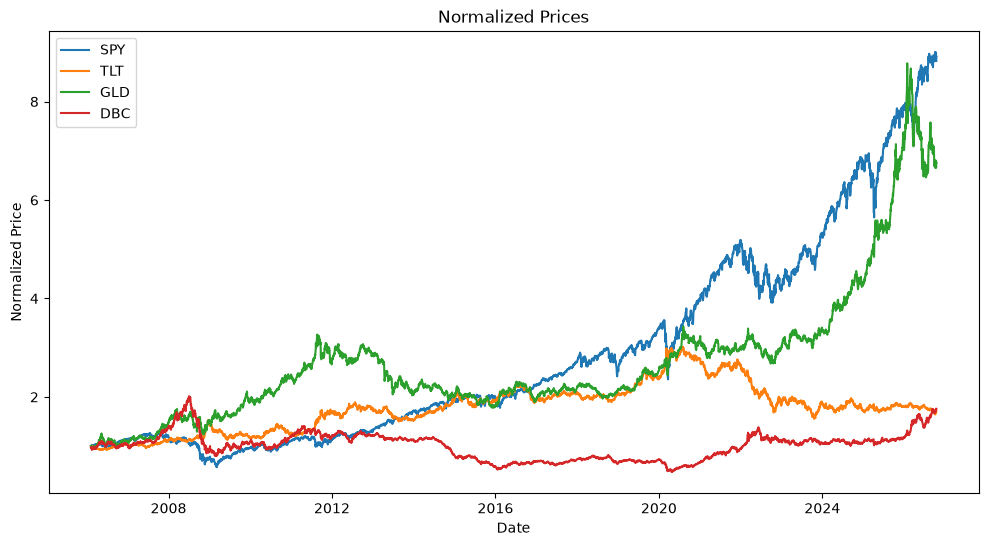

In [59]:
returns_df2 = returns_df[asset_start:]
normalized_df = returns_df2.add(1).cumprod()

plt.figure(figsize=(12, 6))
for asset in ASSETS:
    plt.plot(normalized_df.index, normalized_df[asset], label=asset)
plt.title('Normalized Prices')
plt.xlabel('Date')
plt.ylabel('Normalized Price')
plt.legend()

## Individual performance and risk metrics

In [60]:
for asset in ASSETS:
    returns = returns_df[asset]
    performance(returns, rf_daily)


Parametric analysis of SPY :
 CAGR:             0.108 % 
 Annualized Vol:   0.1852 % 
 Sharpe ratio:     0.5606 
 Sortino ratio:    0.7952 

Parametric analysis of TLT :
 CAGR:             0.0245 % 
 Annualized Vol:   0.1425 % 
 Sharpe ratio:     0.1955 
 Sortino ratio:    0.2779 

Parametric analysis of GLD :
 CAGR:             0.066 % 
 Annualized Vol:   0.1827 % 
 Sharpe ratio:     0.5428 
 Sortino ratio:    0.7641 

Parametric analysis of DBC :
 CAGR:             0.0169 % 
 Annualized Vol:   0.1931 % 
 Sharpe ratio:     0.1554 
 Sortino ratio:    0.2137 



### Equities - SPY (S&P500)

#### Returns computed as a normal distribution

Distribution parameters of SPY 
 Mean:             0.000476 
 Std:              0.0117 
 Skewness:        -0.0107 
 Kurtosis:        11.8702 
 Excess Kurtosis: 8.8702 



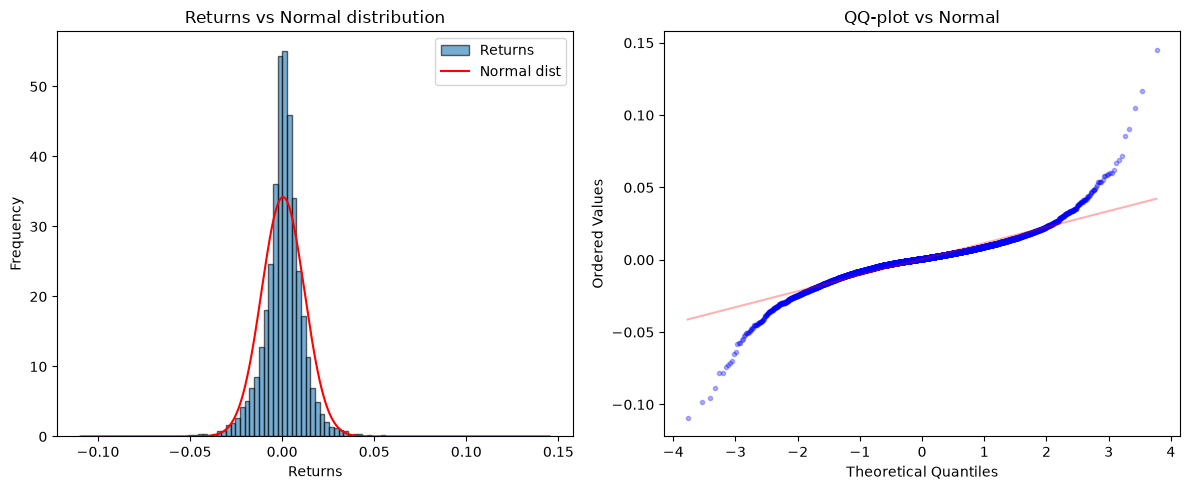

In [61]:
distribution(returns_df['SPY'])

#### Tail risk computing

In [62]:
tail_risks(log_df['SPY'])

Worst day :  2020-03-16 00:00:00 
 returns :  -11.59 %


,Alpha (tail),VaR,CVaR / ES
Confidence Level,,,
95.0%,5.0%,1.794%,3.000%
97.5%,2.5%,2.509%,3.880%
99.0%,1.0%,3.612%,5.294%


#### Drawdowns analysis

<Axes: xlabel='Date'>

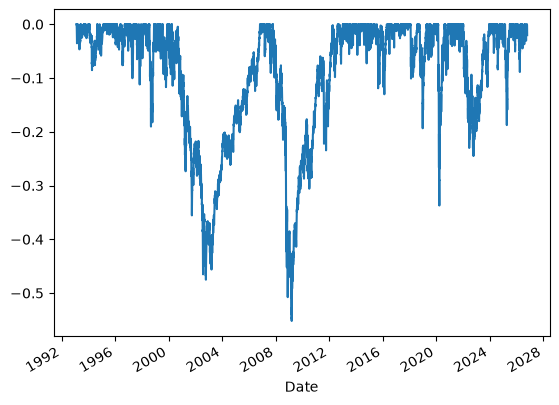

In [63]:
spy_drawdowns2 = drawdowns2(SPY_prices)
spy_drawdowns2["drawdown_series"].plot()   # visualiser

In [64]:
spy_drawdowns2["tuw_table"].sort_values("Max DD (%)").head(12)

,Peak,Trough,Recovery,Max DD (%),TUW (periods),Recovery time
164,2007-10-09,2009-03-09,2012-08-16,-55.19,1224,869.0
140,2000-03-24,2002-10-09,2006-10-26,-47.52,1657,1020.0
319,2020-02-19,2020-03-23,2020-08-10,-33.72,120,97.0
369,2022-01-03,2022-10-12,2023-12-13,-24.50,489,294.0
294,2018-09-20,2018-12-24,2019-04-12,-19.35,140,75.0
114,1998-07-20,1998-08-31,1998-11-23,-19.03,89,59.0
402,2025-02-19,2025-04-08,2025-06-26,-18.76,88,54.0
233,2015-07-20,2016-02-11,2016-04-18,-13.02,188,45.0
131,1999-07-16,1999-10-15,1999-11-17,-11.70,87,23.0
93,1997-10-07,1997-10-27,1997-12-05,-11.20,42,28.0


In [65]:
spy_drawdowns2["longest_dd"]



Peak             2000-03-24 00:00:00
Trough           2002-10-09 00:00:00
Recovery         2006-10-26 00:00:00
Max DD (%)                    -47.52
TUW (periods)                   1657
Recovery time                 1020.0
Name: 140, dtype: object

In [66]:
spy_drawdowns2["deepest_dd"]

Peak             2007-10-09 00:00:00
Trough           2009-03-09 00:00:00
Recovery         2012-08-16 00:00:00
Max DD (%)                    -55.19
TUW (periods)                   1224
Recovery time                  869.0
Name: 164, dtype: object

### Bonds - TLT (20+ Year Treasuries)

#### Returns computed as a normal distribution

Distribution parameters of TLT 
 Mean:             0.000174 
 Std:              0.009 
 Skewness:        0.0561 
 Kurtosis:        3.5019 
 Excess Kurtosis: 0.5019 



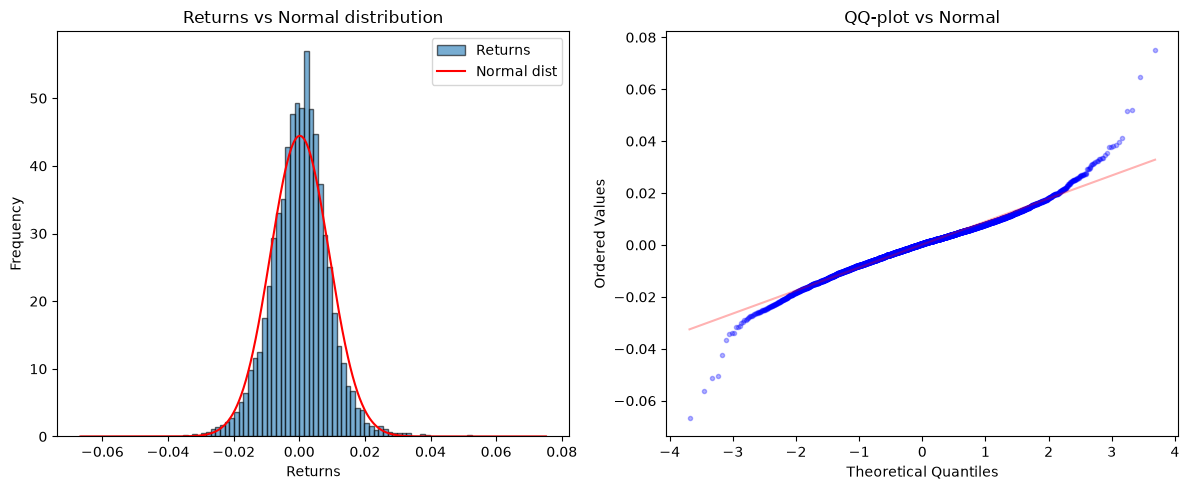

In [67]:
distribution(TLT_returns)

#### Tail risk computing

In [68]:
tail_risks(TLT_log)

Worst day :  2020-03-17 00:00:00 
 returns :  -6.9 %


,Alpha (tail),VaR,CVaR / ES
Confidence Level,,,
95.0%,5.0%,1.456%,1.985%
97.5%,2.5%,1.795%,2.367%
99.0%,1.0%,2.287%,2.905%


#### Drawdowns analysis

<Axes: xlabel='Date'>

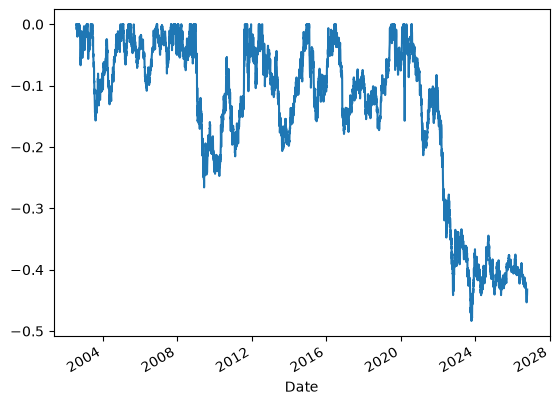

In [69]:
tlt_drawdowns2 = drawdowns2(TLT_prices)
tlt_drawdowns2["drawdown_series"].plot()   # visualiser

In [70]:
tlt_drawdowns2["tuw_table"].sort_values("Max DD (%)").head(12)

,Peak,Trough,Recovery,Max DD (%),TUW (periods),Recovery time
82,2020-08-04,2023-10-19,NaT,-48.35,1558,NaN
49,2008-12-30,2009-06-10,2011-08-18,-26.59,664,553.0
58,2012-07-25,2013-08-21,2014-12-10,-20.66,598,329.0
70,2016-07-08,2016-12-14,2019-07-02,-17.88,750,639.0
65,2015-01-30,2015-06-26,2016-06-09,-15.81,342,240.0
79,2020-03-09,2020-03-18,2020-04-21,-15.73,30,23.0
14,2003-06-13,2003-08-13,2004-12-15,-15.69,380,338.0
54,2011-10-03,2011-10-27,2011-12-19,-10.91,54,36.0
26,2005-06-30,2006-05-12,2006-11-24,-10.84,354,136.0
55,2011-12-19,2012-03-19,2012-05-17,-10.41,103,42.0


In [71]:
tlt_drawdowns2["longest_dd"] #also the deepest dd.



Peak             2020-08-04 00:00:00
Trough           2023-10-19 00:00:00
Recovery                         NaT
Max DD (%)                    -48.35
TUW (periods)                   1558
Recovery time                    NaN
Name: 82, dtype: object

### Gold - GLD

#### Returns computed as a normal distribution

Distribution parameters of GLD 
 Mean:             0.000457 
 Std:              0.0115 
 Skewness:        -0.3066 
 Kurtosis:        6.4067 
 Excess Kurtosis: 3.4067 



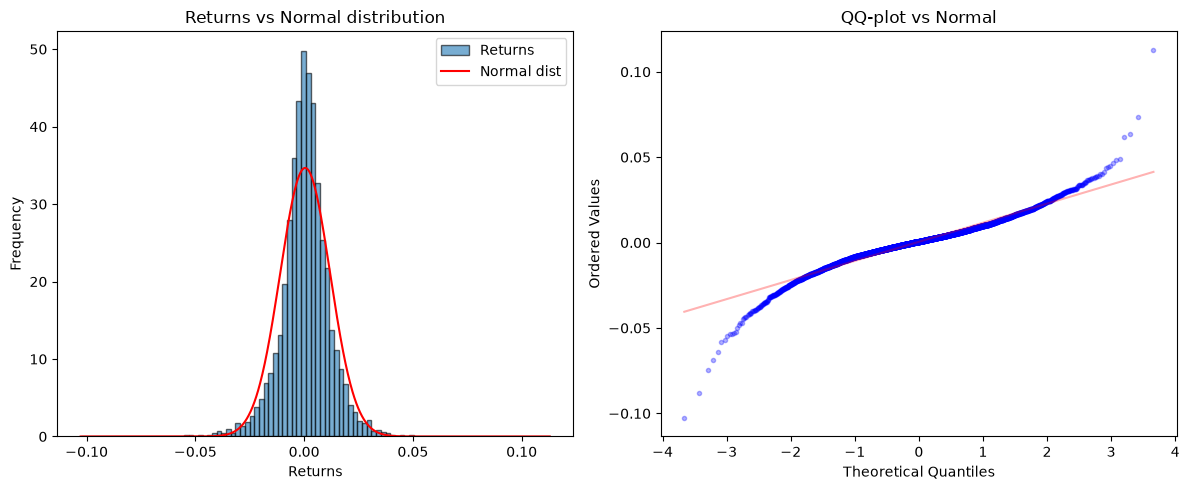

In [72]:
distribution(GLD_returns)

#### Tail risk computing

In [73]:
tail_risks(GLD_log)

Worst day :  2026-01-30 00:00:00 
 returns :  -10.84 %


,Alpha (tail),VaR,CVaR / ES
Confidence Level,,,
95.0%,5.0%,1.813%,2.769%
97.5%,2.5%,2.379%,3.484%
99.0%,1.0%,3.232%,4.540%


#### Drawdowns analysis

<Axes: xlabel='Date'>

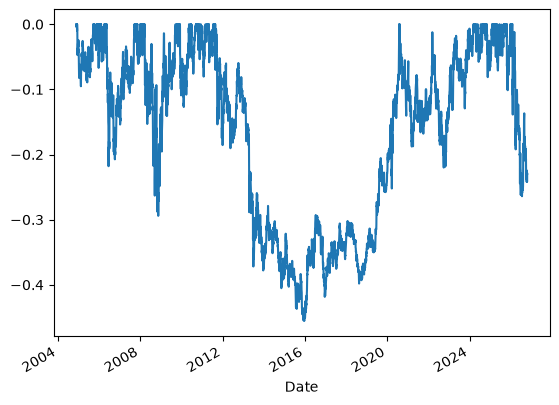

In [74]:
gld_drawdowns2 = drawdowns2(GLD_prices)
gld_drawdowns2["drawdown_series"].plot()   # visualiser

In [75]:
gld_drawdowns2["tuw_table"].sort_values("Max DD (%)").head(12)

,Peak,Trough,Recovery,Max DD (%),TUW (periods),Recovery time
73,2011-08-22,2015-12-17,2020-07-29,-45.56,2248,1160.0
43,2008-03-17,2008-11-12,2009-09-16,-29.41,379,211.0
119,2026-01-29,2026-07-16,NaT,-26.40,180,NaN
75,2020-08-06,2022-09-26,2024-03-04,-22.00,898,360.0
24,2006-05-12,2006-06-14,2007-09-18,-21.79,339,317.0
50,2009-12-02,2010-02-08,2010-05-11,-12.70,109,64.0
114,2025-10-20,2025-11-04,2025-12-22,-10.13,44,33.0
2,2004-12-03,2005-02-08,2005-09-16,-9.52,198,153.0
93,2024-10-30,2024-11-15,2025-01-30,-8.12,61,49.0
62,2010-12-06,2011-01-27,2011-03-01,-8.04,58,22.0


In [76]:
gld_drawdowns2["longest_dd"] #also the deepest dd.



Peak             2011-08-22 00:00:00
Trough           2015-12-17 00:00:00
Recovery         2020-07-29 00:00:00
Max DD (%)                    -45.56
TUW (periods)                   2248
Recovery time                 1160.0
Name: 73, dtype: object

### Commodities - DBC (must be replaced by ^bcom in the future)

#### Returns computed as a normal distribution

Distribution parameters of DBC 
 Mean:             0.000183 
 Std:              0.0122 
 Skewness:        -0.3874 
 Kurtosis:        2.9578 
 Excess Kurtosis: -0.0422 



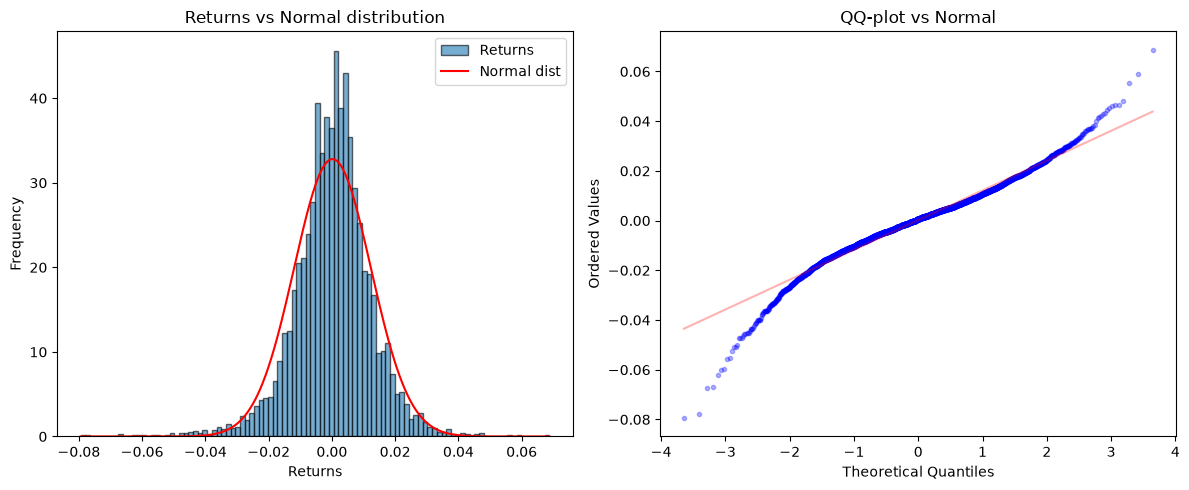

In [77]:
distribution(DBC_returns)

#### Tail risk computing

In [78]:
tail_risks(DBC_log)

Worst day :  2022-03-09 00:00:00 
 returns :  -8.28 %


,Alpha (tail),VaR,CVaR / ES
Confidence Level,,,
95.0%,5.0%,1.932%,2.949%
97.5%,2.5%,2.598%,3.664%
99.0%,1.0%,3.594%,4.672%


#### Drawdowns analysis

<Axes: xlabel='Date'>

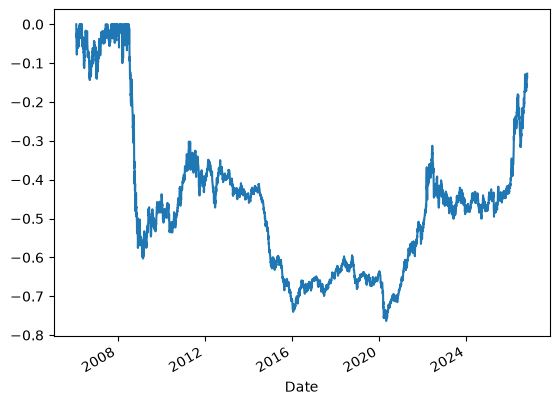

In [79]:
dbc_drawdowns2 = drawdowns2(DBC_prices)
dbc_drawdowns2["drawdown_series"].plot()   # visualiser

In [80]:
dbc_drawdowns2["tuw_table"].sort_values("Max DD (%)").head(12)

,Peak,Trough,Recovery,Max DD (%),TUW (periods),Recovery time
36,2008-07-02,2020-04-27,NaT,-76.36,4601,NaN
6,2006-05-11,2006-09-20,2007-06-14,-14.37,274,183.0
27,2008-03-13,2008-03-20,2008-04-16,-10.01,23,18.0
0,2006-02-06,2006-02-15,2006-04-06,-7.81,42,35.0
31,2008-05-21,2008-06-04,2008-06-09,-6.68,12,3.0
20,2008-01-03,2008-01-23,2008-02-08,-6.00,25,12.0
8,2007-07-13,2007-08-17,2007-09-17,-5.59,45,20.0
29,2008-04-22,2008-05-01,2008-05-06,-5.41,10,3.0
16,2007-11-06,2007-11-13,2007-11-23,-4.82,12,7.0
17,2007-11-23,2007-11-30,2007-12-12,-4.20,13,8.0


In [81]:
dbc_drawdowns2["longest_dd"] #also the deepest dd.



Peak             2008-07-02 00:00:00
Trough           2020-04-27 00:00:00
Recovery                         NaT
Max DD (%)                    -76.36
TUW (periods)                   4601
Recovery time                    NaN
Name: 36, dtype: object

## Multi variate risk study

### Covariance and Correlation matrixes

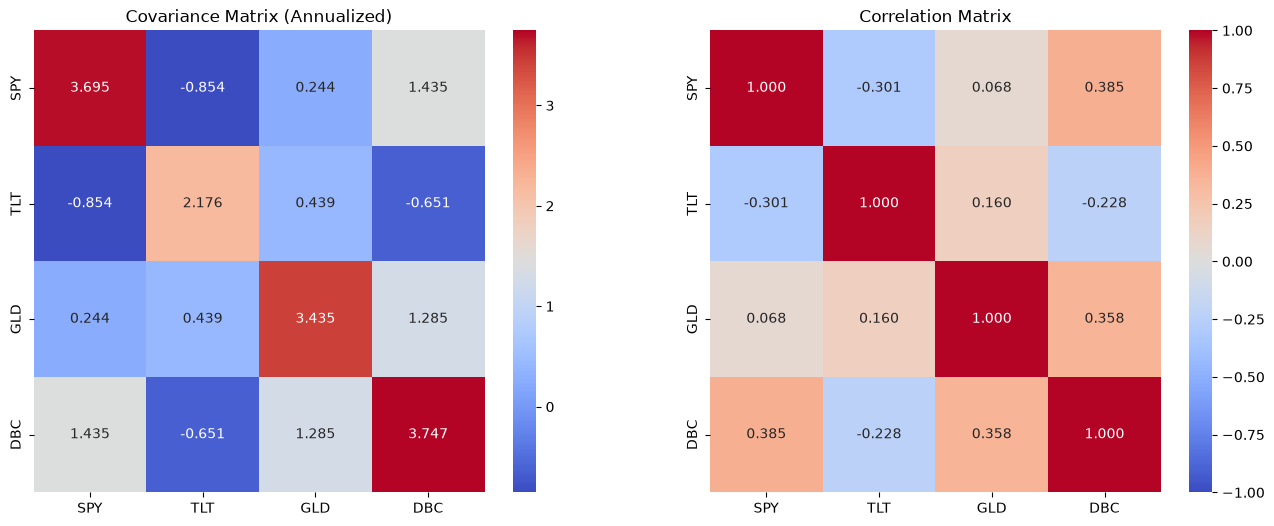

In [82]:
cov_corr_matrix(log_df)

### Pair analysis

This analysis has been performed for each assets pairs. To keep this notebook minimal, only SPY vs Gold is displayed.

#### Overall analysis
Rolling correlation: 126-day and 252-day correlations, showing how their relationship evolves.

Scatter plot + regression: Asset A's returns against Asset B's, with the OLS regression line, beta and \(R^2\).

Rolling volatility: Annualized 126-day volatility of each asset.

Summary statistics

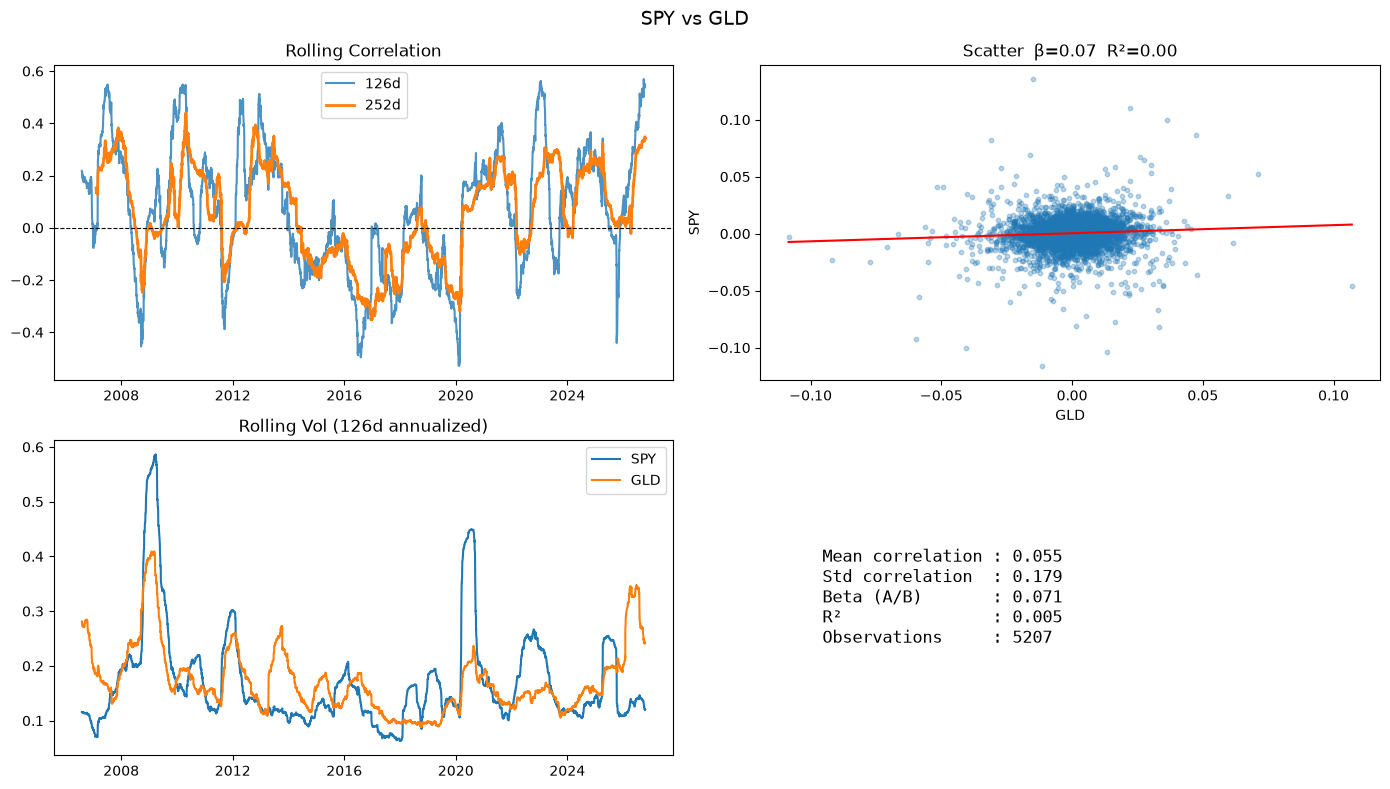

In [83]:
analyze_pair(log_df, asset_a= "SPY", asset_b= "GLD", windows = [126, 252])


#### Correlation during negative events

E[GLD / SPY < 0]

Overall Correlation: 0.0684 
 
When SPY is < 0: 
Correlation: 0.0134 
Beta: 0.0166 
 
When: SPY is > 0: 
Correlation: 0.0386 
Beta: 0.0488 
 
No of days of SPY < 0: 2331 
Total no of observed days: 5207 
pct_obs: 0.448 



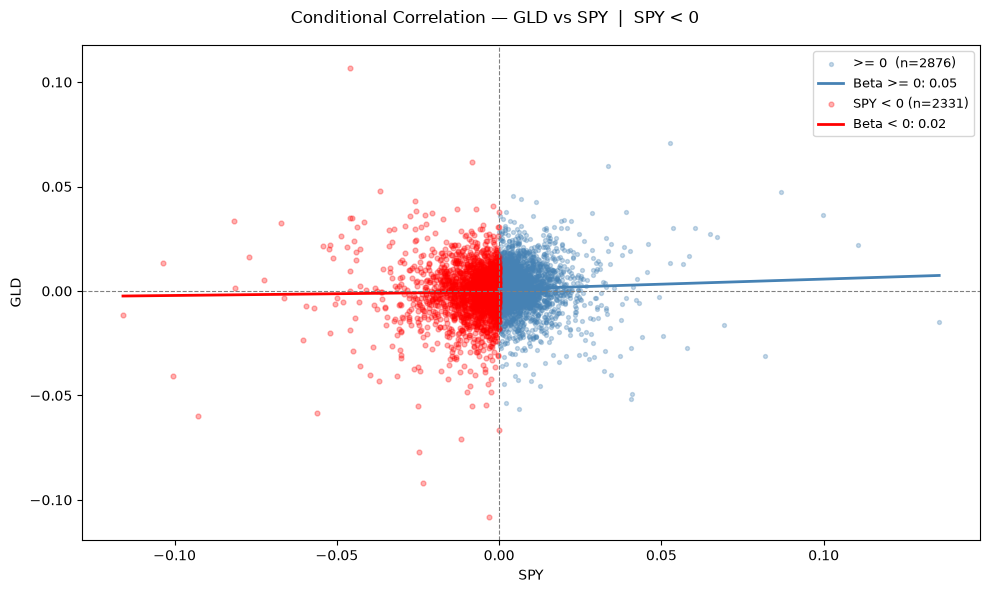

In [84]:
conditional_correlation(log_df, 'GLD', 'SPY', condition_asset='SPY')

#### Copula plot

Tail threshold  : 10%
Lower tail coef : 0.18  (1.0 = Gaussian)
Upper tail coef : 0.17  (1.0 = Gaussian)
Kendall τ       : 0.051
Spearman ρ      : 0.074


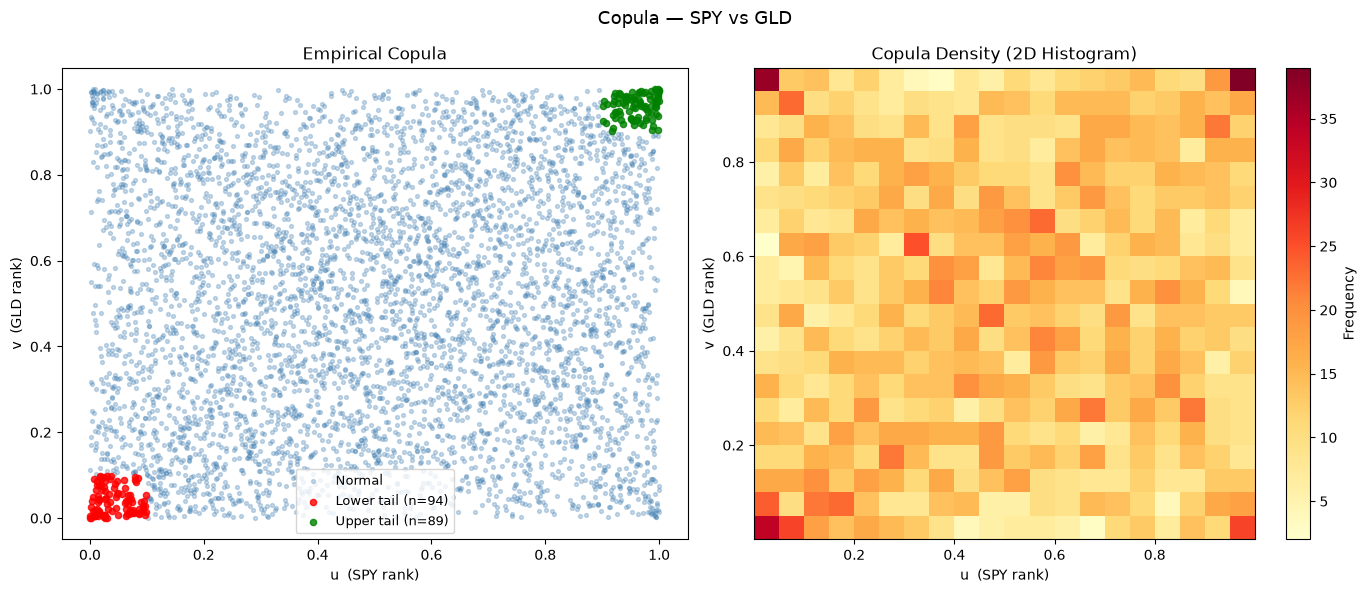

In [85]:
copula(log_df, asset_a= "SPY", asset_b= "GLD")

# Risk metrics in regimes

Regime 1 = Econ + / Policy +

Regime 2 = Econ + / Policy -

Regime 3 = Econ - / Policy +

Regime 4 = Econ - / Policy -

## Asset performance

In [86]:
regime_df = pd.concat(
    {"regime": df["regime"],
     "returns": returns_df},
    axis=1)

regime_df = regime_df[asset_start:]

regime1 = regime_df.loc[regime_df["regime"]["regime"] == 1] 
regime2 = regime_df.loc[regime_df["regime"]["regime"] == 2] 
regime3 = regime_df.loc[regime_df["regime"]["regime"] == 3] 
regime4 = regime_df.loc[regime_df["regime"]["regime"] == 4] 

/var/folders/lc/5629m9_j0qv09m42l0cy4hd40000gn/T/ipykernel_77599/2365181669.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  regime_df = pd.concat(


### Regime 1 - Econ + / Policy +

In [87]:
fig1 = plot_regime_compounded(regime1["returns"], txtregime1)
fig1.show()

regime_metrics(regime1["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,1462.0,0.199486,0.145320,1.324600,-0.161210,0.581395
TLT,1462.0,0.030310,0.120848,0.307549,-0.251661,0.523256
GLD,1462.0,0.131684,0.168236,0.820050,-0.310450,0.526676
DBC,1462.0,-0.021904,0.159396,-0.059164,-0.451261,0.510260


### Regime 2 - Econ + / Policy -

In [88]:
fig2 = plot_regime_compounded(regime2["returns"], txtregime2)
fig2.show()

regime_metrics(regime2["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,1308.0,0.095132,0.149632,0.682356,-0.220518,0.531346
TLT,1308.0,-0.041671,0.137296,-0.241411,-0.352655,0.486239
GLD,1308.0,0.054621,0.173693,0.393277,-0.217968,0.529052
DBC,1308.0,0.110386,0.184352,0.660558,-0.293957,0.526758


### Regime 3 - Econ - / Policy +

In [89]:
fig3 = plot_regime_compounded(regime3["returns"], txtregime3)
fig3.show()

regime_metrics(regime3["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,2124.0,0.079418,0.235726,0.442108,-0.479487,0.543315
TLT,2124.0,0.090156,0.166640,0.601285,-0.265854,0.534369
GLD,2124.0,0.070923,0.194902,0.449370,-0.471119,0.531544
DBC,2123.0,-0.006370,0.207193,0.073071,-0.531217,0.512482


### Regime 4 - Econ - / Policy -

In [90]:
fig4 = plot_regime_compounded(regime4["returns"], txtregime4)
fig4.show()

regime_metrics(regime4["returns"])

,n_obs,CAGR,Vol,Sharpe,MaxDD,HitRate
SPY,313.0,0.005216,0.211695,0.130711,-0.177330,0.523962
TLT,313.0,-0.108970,0.163540,-0.623771,-0.228736,0.501597
GLD,313.0,0.314807,0.230946,1.299460,-0.237979,0.546326
DBC,313.0,0.177930,0.261370,0.757631,-0.283681,0.530351


# To be continued